In [1]:
!pip install -q pycocotools

In [2]:
import os
import random
import requests
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
from pycocotools.coco import COCO

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
import os

if not os.path.exists("annotations_trainval2017.zip"):
    !wget -q http://images.cocodataset.org/annotations/annotations_trainval2017.zip

print("COCO annotation ZIP downloaded successfully!")

COCO annotation ZIP downloaded successfully!


In [4]:
import os

if not os.path.exists("annotations"):
    !unzip -q annotations_trainval2017.zip

print("COCO annotations extracted successfully!")

COCO annotations extracted successfully!


In [5]:
from pycocotools.coco import COCO

annFile = "annotations/instances_val2017.json"

coco = COCO(annFile)

print("COCO annotations loaded successfully!")

loading annotations into memory...
Done (t=0.68s)
creating index...
index created!
COCO annotations loaded successfully!


In [6]:
traffic_classes = [
    "person",
    "bicycle",
    "car",
    "motorcycle",
    "bus",
    "truck",
    "traffic light"
]

catIds = coco.getCatIds(catNms=traffic_classes)

cats = coco.loadCats(catIds)

print("TRAFFIC RELATED COCO CATEGORIES\n")

for cat in cats:
    print("•", cat["name"])

TRAFFIC RELATED COCO CATEGORIES

• person
• bicycle
• car
• motorcycle
• bus
• truck
• traffic light


In [7]:
imgIds = []

for catId in catIds:
    imgIds += coco.getImgIds(catIds=[catId])

imgIds = list(set(imgIds))

print("Total Traffic Images Found:", len(imgIds))

Total Traffic Images Found: 3001


In [18]:
# Find images containing multiple traffic categories
imgIds = []

for catId in catIds:
    imgIds += coco.getImgIds(catIds=[catId])

imgIds = list(set(imgIds))

# Select an image containing at least 3 traffic categories
selected_img = None

for image_id in random.sample(imgIds, len(imgIds)):
    anns_temp = coco.loadAnns(coco.getAnnIds(imgIds=[image_id]))

    categories = set(ann["category_id"] for ann in anns_temp)

    if len(categories.intersection(catIds)) >= 3:
        selected_img = image_id
        break

img_info = coco.loadImgs([selected_img])[0]

print("Selected Image:", img_info["file_name"])
print("Image ID:", img_info["id"])

Selected Image: 000000356612.jpg
Image ID: 356612


In [19]:
img_url = img_info["coco_url"]

image_file = img_info["file_name"]

if not os.path.exists(image_file):
    r = requests.get(img_url)
    open(image_file, "wb").write(r.content)

print("Image downloaded successfully!")
print("Saved Image:", image_file)

Image downloaded successfully!
Saved Image: 000000356612.jpg


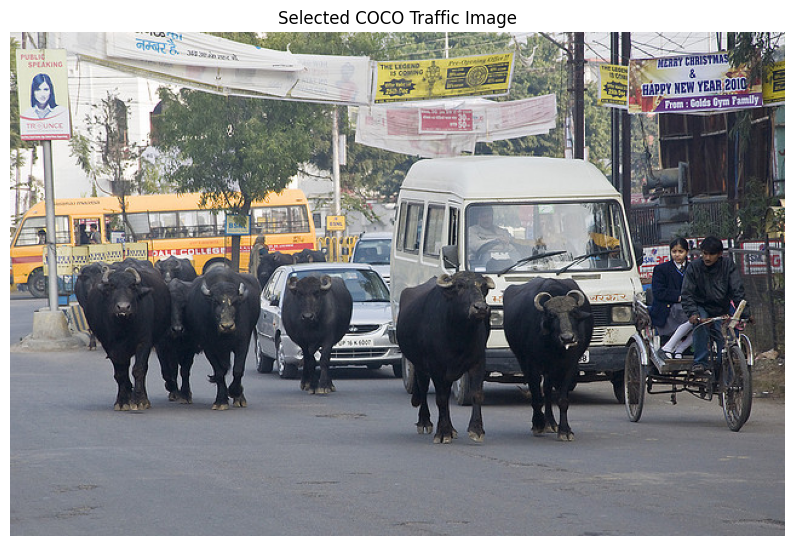

In [20]:
image = Image.open(image_file)

plt.figure(figsize=(10, 7))
plt.imshow(image)

plt.title("Selected COCO Traffic Image")
plt.axis("off")

plt.show()

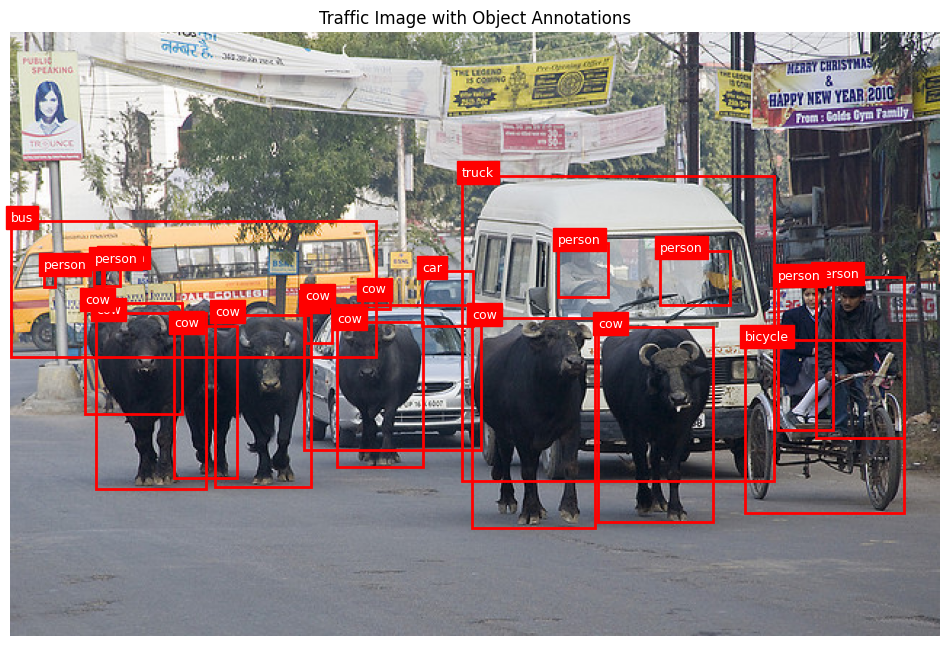

In [21]:
# Get annotations for the selected image
annIds = coco.getAnnIds(imgIds=img_info["id"])
anns = coco.loadAnns(annIds)

# Display image
fig, ax = plt.subplots(figsize=(12, 8))
ax.imshow(image)

# Draw bounding boxes and labels
for ann in anns:
    x, y, w, h = ann["bbox"]

    category = coco.loadCats([ann["category_id"]])[0]["name"]

    rect = patches.Rectangle(
        (x, y), w, h,
        linewidth=2,
        edgecolor="red",
        facecolor="none"
    )

    ax.add_patch(rect)
    ax.text(x, y, category, color="white",
            backgroundcolor="red", fontsize=9)

plt.title("Traffic Image with Object Annotations")
plt.axis("off")
plt.show()

In [22]:
from collections import Counter

# Count objects by category
object_counts = Counter()

for ann in anns:
    category = coco.loadCats([ann["category_id"]])[0]["name"]
    object_counts[category] += 1

print("Object Detection Summary:")
for category, count in object_counts.items():
    print(f"{category}: {count}")

Object Detection Summary:
car: 2
bus: 1
person: 7
bicycle: 1
truck: 1
cow: 9


In [23]:
print("Detailed Object Annotations:")

for i, ann in enumerate(anns, start=1):
    category = coco.loadCats([ann["category_id"]])[0]["name"]
    print(f"Object {i}: {category}")

Detailed Object Annotations:
Object 1: car
Object 2: car
Object 3: bus
Object 4: person
Object 5: person
Object 6: bicycle
Object 7: truck
Object 8: person
Object 9: person
Object 10: cow
Object 11: cow
Object 12: cow
Object 13: cow
Object 14: cow
Object 15: cow
Object 16: cow
Object 17: person
Object 18: person
Object 19: person
Object 20: cow
Object 21: cow


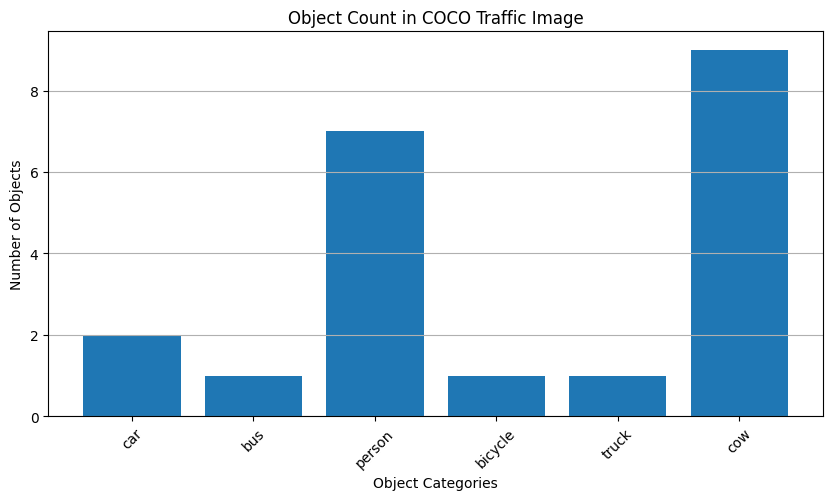

In [24]:
# Prepare data for the graph
categories = list(object_counts.keys())
counts = list(object_counts.values())

# Create bar graph
plt.figure(figsize=(10, 5))
plt.bar(categories, counts)

plt.xlabel("Object Categories")
plt.ylabel("Number of Objects")
plt.title("Object Count in COCO Traffic Image")
plt.xticks(rotation=45)
plt.grid(axis="y")
plt.show()

In [25]:
total_objects = sum(object_counts.values())

print("Object Distribution:")

for category, count in object_counts.items():
    percentage = (count / total_objects) * 100
    print(f"{category}: {percentage:.2f}%")

Object Distribution:
car: 9.52%
bus: 4.76%
person: 33.33%
bicycle: 4.76%
truck: 4.76%
cow: 42.86%


In [26]:
# Calculate bounding box areas
box_areas = []

for ann in anns:
    x, y, w, h = ann["bbox"]
    area = w * h
    box_areas.append(area)

# Display statistics
print("Bounding Box Analysis")
print("Total Objects:", len(box_areas))
print("Small Objects:", sum(1 for a in box_areas if a < 32**2))
print("Medium Objects:", sum(1 for a in box_areas if 32**2 <= a < 96**2))
print("Large Objects:", sum(1 for a in box_areas if a >= 96**2))

Bounding Box Analysis
Total Objects: 21
Small Objects: 5
Medium Objects: 10
Large Objects: 6


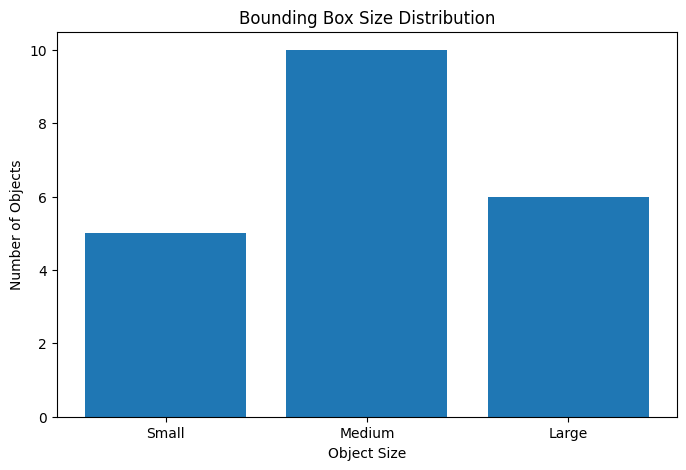

In [27]:
# Categorize bounding box sizes
size_labels = ["Small", "Medium", "Large"]

size_counts = [
    sum(1 for a in box_areas if a < 32**2),
    sum(1 for a in box_areas if 32**2 <= a < 96**2),
    sum(1 for a in box_areas if a >= 96**2)
]

# Plot graph
plt.figure(figsize=(8, 5))
plt.bar(size_labels, size_counts)

plt.xlabel("Object Size")
plt.ylabel("Number of Objects")
plt.title("Bounding Box Size Distribution")
plt.show()

In [28]:
# Get image dimensions
width, height = image.size

print("Image Quality Analysis")
print("Image Width:", width)
print("Image Height:", height)
print("Total Pixels:", width * height)

# Classify resolution
if width < 640 or height < 480:
    print("Resolution: Low")
elif width < 1280 or height < 720:
    print("Resolution: Medium")
else:
    print("Resolution: High")


Image Quality Analysis
Image Width: 640
Image Height: 416
Total Pixels: 266240
Resolution: Low


In [29]:
import numpy as np

# Convert image to grayscale
gray_image = np.array(image.convert("L"))

# Calculate average brightness
brightness = np.mean(gray_image)

print("Image Brightness:", round(brightness, 2))

if brightness < 80:
    print("Image Condition: Dark")
elif brightness < 180:
    print("Image Condition: Normal")
else:
    print("Image Condition: Bright")

Image Brightness: 124.16
Image Condition: Normal


In [30]:
# Calculate image contrast using standard deviation
contrast = np.std(gray_image)

print("Image Contrast:", round(contrast, 2))

if contrast < 40:
    print("Contrast Level: Low")
elif contrast < 70:
    print("Contrast Level: Medium")
else:
    print("Contrast Level: High")

Image Contrast: 60.13
Contrast Level: Medium


In [31]:
print("========== DATASET AUDIT SUMMARY ==========")

print("\n1. Image Information")
print("Image Name:", image_file)
print("Resolution:", width, "x", height)

print("\n2. Object Detection")
print("Total Annotated Objects:", total_objects)

for category, count in object_counts.items():
    print(f"{category}: {count}")

print("\n3. Object Size Distribution")
for label, count in zip(size_labels, size_counts):
    print(f"{label}: {count}")

print("\n4. Image Quality")
print("Brightness:", round(brightness, 2))
print("Contrast:", round(contrast, 2))

print("\n========== AUDIT COMPLETED ==========")

========== DATASET AUDIT SUMMARY ==========

1. Image Information
Image Name: 000000356612.jpg
Resolution: 640 x 416

2. Object Detection
Total Annotated Objects: 21
car: 2
bus: 1
person: 7
bicycle: 1
truck: 1
cow: 9

3. Object Size Distribution
Small: 5
Medium: 10
Large: 6

4. Image Quality
Brightness: 124.16
Contrast: 60.13

========== AUDIT COMPLETED ==========


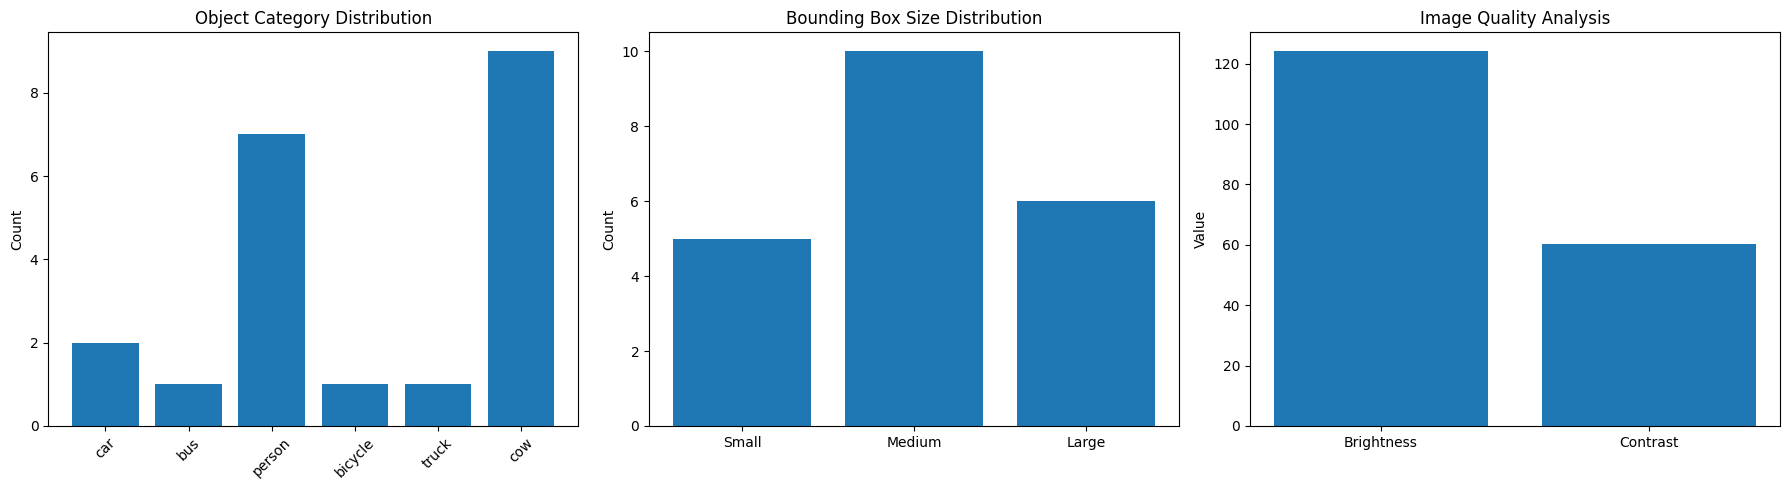

In [32]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Object count
axes[0].bar(categories, counts)
axes[0].set_title("Object Category Distribution")
axes[0].set_ylabel("Count")
axes[0].tick_params(axis="x", rotation=45)

# Object size
axes[1].bar(size_labels, size_counts)
axes[1].set_title("Bounding Box Size Distribution")
axes[1].set_ylabel("Count")

# Brightness and contrast
axes[2].bar(
    ["Brightness", "Contrast"],
    [brightness, contrast]
)
axes[2].set_title("Image Quality Analysis")
axes[2].set_ylabel("Value")

plt.tight_layout()
plt.show()